<a href="https://colab.research.google.com/github/miguel-rs7/Rag-radiografias/blob/main/Github%20embedings%20Xray.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
%cd /content
!rm -rf rag-radiografias
!git clone https://github.com/miguel-rs7/rag-radiografias.git
%cd rag-radiografias
!pip install -q -r requirements.txt
from google.colab import drive
drive.mount('/content/drive')

/content
Cloning into 'rag-radiografias'...
remote: Enumerating objects: 46, done.
remote: Counting objects: 100% (46/46), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 46 (delta 15), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (46/46), 17.30 KiB | 1.44 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/rag-radiografias
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
import sys; sys.path.insert(0, "/content/rag-radiografias")
import kagglehub
from google.colab import userdata
from src import embeddings
from src.db import conectar
from src.rag import muestra, indexar, buscar, evaluar

embeddings.iniciar(userdata.get("GEMINI_API_KEY"))
col, db = conectar()
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


In [28]:
rutas = muestra(path, "train", 100)
indexar(col, db, rutas, "train")
for id_, diag, dist in buscar(col, db, rutas[0]):
    print(id_, diag, dist)
print(f"Acierto: {evaluar(col, db, muestra(path, 'test', 25)):.0%}")

200 ya indexadas, 0 pendientes
NORMAL_IM-0115-0001 NORMAL 0.0
NORMAL_IM-0227-0001 NORMAL 0.006
NORMAL_IM-0278-0001 NORMAL 0.006
NORMAL_IM-0269-0001 NORMAL 0.006
NORMAL_IM-0135-0001 NORMAL 0.006
Acierto: 90%


Diagnóstico de la consulta: PNEUMONIA


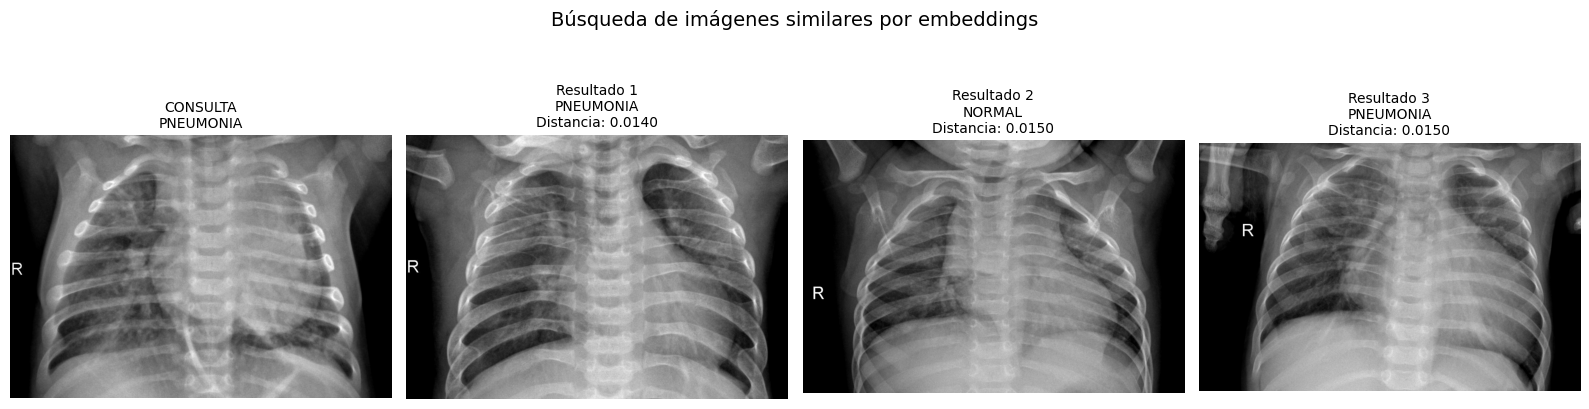


Resultados recuperados:
1. PNEUMONIA_person1001_bacteria_2932 | PNEUMONIA | Distancia: 0.0140
2. NORMAL_IM-0128-0001 | NORMAL | Distancia: 0.0150
3. PNEUMONIA_person1057_bacteria_2991 | PNEUMONIA | Distancia: 0.0150


In [29]:
import os
import matplotlib.pyplot as plt
from PIL import Image
from src.rag import buscar, muestra

# 1. Seleccionar una radiografía de neumonía del conjunto de prueba
rutas_test = muestra(path, "test", 100)

ruta_consulta = next(
    ruta for ruta in rutas_test
    if os.path.basename(os.path.dirname(ruta)) == "PNEUMONIA"
)

print("Diagnóstico de la consulta: PNEUMONIA")

# 2. Buscar las 3 imágenes más similares en la base vectorial
resultados = buscar(col, db, ruta_consulta)[:3]

# 3. Mostrar consulta y resultados en una sola figura
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

# Imagen de consulta
axes[0].imshow(Image.open(ruta_consulta).convert("RGB"))
axes[0].set_title("CONSULTA\nPNEUMONIA", fontsize=10)
axes[0].axis("off")

# Imágenes recuperadas
for i, (identificador, diagnostico, distancia) in enumerate(resultados, 1):
    registro = db.execute(
        "SELECT ruta FROM estudios WHERE id = ?",
        (identificador,)
    ).fetchone()

    if registro and os.path.exists(registro[0]):
        axes[i].imshow(Image.open(registro[0]).convert("RGB"))
        axes[i].set_title(
            f"Resultado {i}\n{diagnostico}\nDistancia: {distancia:.4f}",
            fontsize=10
        )
    else:
        axes[i].set_title(f"Resultado {i}\nImagen no encontrada")

    axes[i].axis("off")

plt.suptitle("Búsqueda de imágenes similares por embeddings", fontsize=14)
plt.tight_layout()
plt.show()

# 4. Resumen textual
print("\nResultados recuperados:")
for i, (identificador, diagnostico, distancia) in enumerate(resultados, 1):
    print(f"{i}. {identificador} | {diagnostico} | Distancia: {distancia:.4f}")